# 9.4 Time-Series Statistics

**Goal:** diagnose temporal structure and build forecasts without leaking future observations.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Information Theory](1_Information-Theory.ipynb)
2. [Statistical Learning Theory](2_Statistical-Learning-Theory.ipynb)
3. [Advanced Probability](3_Advanced-Probability.ipynb)
4. [Time-Series Statistics](4_Time-Series-Statistics.ipynb)
5. [Statistical Computing](5_Statistical-Computing.ipynb)
6. [Specialized Statistical Methods](6_Specialized-Statistical-Methods.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Trend and Seasonality

A trend is persistent change in a series' level; seasonality is a repeating pattern tied to a period such as day-of-week. An additive decomposition writes observation as trend+seasonal+remainder; multiplicative patterns can motivate logs when positive. Cycles need not have fixed calendar periods. Missing dates, irregular spacing, and changed measurement rules should be audited before interpreting patterns.

**Worked example:** generate daily values with a linear trend and weekly sinusoidal component. A random row split can train on future patterns and overstate realistic forecasting performance; use temporal backtesting and feature windows available at each forecast origin.

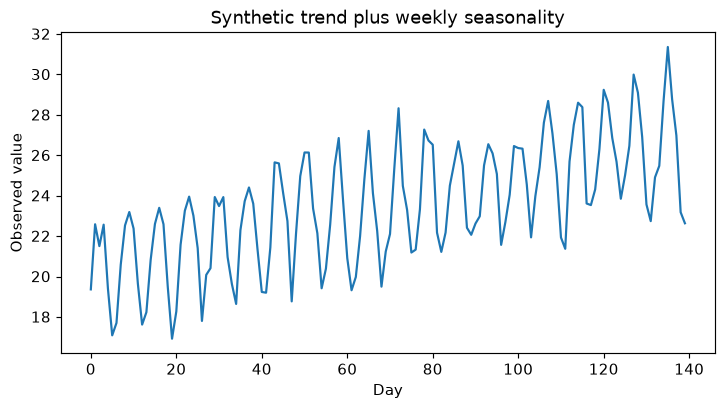

In [2]:
t=np.arange(140);series=20+.05*t+3*np.sin(2*np.pi*t/7)+rng.normal(0,.8,len(t))
fig,ax=plt.subplots();ax.plot(t,series)
ax.set(title="Synthetic trend plus weekly seasonality",xlabel="Day",ylabel="Observed value");fig.tight_layout();plt.show()

## 2. Stationarity, Autocorrelation, Partial Autocorrelation, and White Noise

Weak stationarity assumes finite second moments, constant mean, and covariance depending only on lag. Strict stationarity requires all finite-dimensional distributions to be invariant under time shifts and need not imply finite moments. **White noise** is typically zero-mean, constant-variance, uncorrelated across times; Gaussian/IID white noise is a stronger assumption.

Autocorrelation (ACF) compares a series with its lagged values. Partial autocorrelation (PACF) measures residual linear association at a lag after controlling intermediate lags; it helps distinguish direct linear lag structure, not causal effects. Sample estimates fluctuate and nominal ACF bands are approximations under a specified null. Trend can create apparent persistent autocorrelation, so inspect mean structure first.

In [3]:
def acf(x,maxlag):
    z=np.asarray(x)-np.mean(x);den=z@z
    return np.array([1.]+[np.dot(z[k:],z[:-k])/den for k in range(1,maxlag+1)])
def pacf_one(x,k):
    if k==1:return np.corrcoef(x[1:],x[:-1])[0,1]
    n=len(x);controls=np.column_stack([np.ones(n-k)]+[x[k-j:n-j] for j in range(1,k)])
    a=x[k:];b=x[:-k]
    ra=a-controls@np.linalg.lstsq(controls,a,rcond=None)[0]
    rb=b-controls@np.linalg.lstsq(controls,b,rcond=None)[0]
    return np.corrcoef(ra,rb)[0,1]
print("First five sample ACF values:",acf(series,5))
print("Sample PACF at lag 2:",pacf_one(series,2))

First five sample ACF values: [ 1.          0.73371261  0.31283414 -0.04211504 -0.05649805  0.26099605]
Sample PACF at lag 2: -0.5147602445994474


## 3. Moving Averages and Exponential Smoothing

A trailing rolling mean smooths recent observed values. It is not the same as a **moving-average stochastic model**, whose terms are current and lagged unobserved innovations. Centered rolling windows use future values and are unsuitable as real-time forecast features without a shift.

Simple exponential smoothing updates a level $\ell_t=\alpha y_t+(1-\alpha)\ell_{t-1}$ and forecasts the next value from the current level. Trend/seasonal extensions such as Holt/Holt–Winters add components and assumptions. Tune smoothing only on past training/validation windows. Smoothing suppresses short-term variation but may lag turning points.

In [4]:
window=7;trailing=np.convolve(series,np.ones(window)/window,mode="valid")
level=np.empty(len(series));level[0]=series[0]
for i in range(1,len(series)):level[i]=.3*series[i]+.7*level[i-1]
print("Next simple-smoothed level forecast:",level[-1])
print("Final trailing seven-day mean:",trailing[-1])

Next simple-smoothed level forecast: 25.26072687204411
Final trailing seven-day mean: 26.72863249806475


## 4. AR, MA and ARIMA

An AR(p) model predicts current values from p lagged values plus innovation. An MA(q) model combines current and q lagged innovations. ARMA combines both; ARIMA(p,d,q) applies ARMA to d-th differences. Seasonal ARIMA adds seasonal lag/differencing structure. Differencing can remove some nonstationary level structure but over-differencing can introduce artifacts.

For AR(1), $X_t=c+\phi X_{t-1}+\epsilon_t$ is covariance stationary with finite-variance IID innovations when |φ|<1, having mean c/(1−φ). A unit root φ=1 gives another regime. Fit order and diagnose residual structure rather than assume stationarity from a plot. Conditional least squares below fits an AR(1); it is not a general MA/ARIMA maximum-likelihood solver.

In [5]:
ar=np.zeros(250)
for i in range(1,len(ar)):ar[i]=.4+.7*ar[i-1]+rng.normal()
train=ar[:200];design=np.column_stack([np.ones(len(train)-1),train[:-1]])
c,phi=np.linalg.lstsq(design,train[1:],rcond=None)[0]
res=train[1:]-design@np.array([c,phi]);sigma=res.std(ddof=2)
print("Fitted AR intercept/lag:",c,phi,"innovation SD:",sigma)
print("First differences of original seasonal series:",np.diff(series)[:5])

Fitted AR intercept/lag: 0.3415476208213356 0.7745700641529892 innovation SD: 1.020623362341841
First differences of original seasonal series: [ 3.22244945 -1.08022882  1.06054593 -3.15928401 -2.3174063 ]


## 5. Forecasting Intervals and Change Point Detection

For a fixed-parameter Gaussian AR(1), h-step forecast-error variance is $\sigma²\sum_{j=0}^{h-1}\phi^{2j}$. Estimated-parameter uncertainty and misspecification add uncertainty not included in that simple plug-in interval. Coverage must be checked by horizon using rolling-origin evaluation; train/test residual errors are not interchangeable.

A **change point** is a structural change in level, variance, dependence, or another distribution feature. CUSUM and segmented losses are common tools. Searching many candidate points changes inference; an apparent best split is a descriptive candidate, not an unadjusted significance result. Online detection has delay/false-alarm tradeoffs and cannot use future records.

**Example:** recursively forecast a held-out AR series and show a simple maximum-level-split candidate on an artificially shifted sequence.

In [6]:
h=20;forecast=[];value=train[-1]
for _ in range(h):value=c+phi*value;forecast.append(value)
se=sigma*np.sqrt(np.cumsum(phi**(2*np.arange(h))))
print("First forecast and approximate 95% limits:",forecast[0],forecast[0]-1.96*se[0],forecast[0]+1.96*se[0])
changed=np.r_[rng.normal(0,1,60),rng.normal(3,1,60)]
candidates=np.arange(15,105)
losses=[np.sum((changed[:k]-changed[:k].mean())**2)+np.sum((changed[k:]-changed[k:].mean())**2) for k in candidates]
print("Best descriptive split:",candidates[np.argmin(losses)],"true synthetic split:",60)

First forecast and approximate 95% limits: 0.36768178385164085 -1.6327400063383675 2.3681035740416494
Best descriptive split: 60 true synthetic split: 60


## AI/ML application and interpretation

Time-series statistics support demand forecasting, drift monitoring, and sequential experiments. Preserve time order, horizon-specific availability, repeated entities, and regime changes. Good in-sample fit or stationary-looking residuals alone do not establish reliable future intervals.

## Practice

1. Does white noise necessarily mean independent Gaussian data?
2. How does a rolling average differ from an MA model?
3. Why can a centered smoother leak future information?
4. Does the smallest segmented loss supply an unadjusted valid p-value for a change point?

## Solutions

1. Not under the weak uncorrelated definition; IID Gaussian white noise is stronger.
2. One averages observed values, while the stochastic model combines latent innovations.
3. It uses values after the forecast origin, which would not yet be available.
4. No. Searching candidate points is a selection process requiring a suitable reference/calibration procedure.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](5_Statistical-Computing.ipynb).